In [2]:
# import cython
import numpy as np
import matplotlib.pyplot as plt 
import glob
import os

from joblib import Parallel, delayed
import multiprocessing as mp

In [3]:
# Check that MPS is available
import torch
from unet import UNet, TransformerNet
import torchvision.transforms as transforms

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

# if not torch.backends.mps.is_available():
#     if not torch.backends.mps.is_built():
#         print("MPS not available because the current PyTorch install was not "
#               "built with MPS enabled.")
#     else:
#         print("MPS not available because the current MacOS version is not 12.3+ "
#               "and/or you do not have an MPS-enabled device on this machine.")

# else:
#     device = torch.device("mps")

cuda:0


In [4]:
def dist_loss(input, model): # radius is the maxmum loss between two points. 
    loss = 0.0
    for point in input:
        error = (np.min(np.sum((model-point)**2, axis = 1)))
        loss += error
    loss = loss/input.shape[0]
    # print(input.shape[0])
    # print(model.shape)
    return loss

In [5]:
target_size = [512,408]
saved_model_dir = 'saved_model/'
savedmodel_list = glob.glob1(saved_model_dir,'TOPHAT_checkpoint_epoch_*')
savedmodel_list.sort()
print(len(savedmodel_list))

testfiles = glob.glob1('VIPIR_PROC/labeled/','*.npy')
testfiles.sort()
evalresult = {}

print(len(testfiles))


21
200


In [19]:
outdir = 'Testfitting_eval_model/'
# evalresult = np.load(outdir+'evalresult_file.npy', allow_pickle=True, fix_imports=True)[()]
print(len(evalresult))

0


In [20]:
model = UNet(n_channels=1, n_classes=4, input_size=target_size, in_dropout_p = 0.35, dropout_p=0.35)
model = model.to(device=device)

batchsize = 10

for f in savedmodel_list[:]:
    if not os.path.exists(outdir+f):
        os.makedirs(outdir+f)
    state_data = torch.load(saved_model_dir+f, weights_only=True)
    model.load_state_dict(state_data['model_state_dict'])
    model.eval()
    with torch.inference_mode():
        for ii in range(len(testfiles)//batchsize):
            img = []
            names = []
            for jj in range(batchsize):
                file = testfiles[ii*batchsize + jj]
                testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]
                testimage = torch.from_numpy(testdata['mask_full']).float()
                testimage = testimage[None,None,:,:]
                img += [testimage]
                names += [file]

            img = torch.cat(img,dim=0)
            img = img.to('cuda')
            label = model(img)
            
            for i in range(batchsize):
                img1,label1 = img[i],label[i]
                label1 = label1.squeeze().to('cpu')
                imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().numpy()
                imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().numpy()

                np.save(outdir+f'{f}/{names[i]}', {'imgO': imgO, 'imgX': imgX})
            
            del label; del img; del names
    del state_data
                

In [21]:
def eval_one_file (outdir, file):
    segresult = np.load(outdir+file, allow_pickle=True, fix_imports=True)[()]
    testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]
    labeldata = np.load('VIPIR_PROC/labeled/' + file, allow_pickle=True, fix_imports=True)[()]

    imgO = segresult['imgO']
    imgX = segresult['imgX']

    Y, X = imgO.nonzero()
    inputO = np.vstack((X,Y)).T

    Y, X = imgX.nonzero()
    inputX = np.vstack((X,Y)).T

    otrace = labeldata['otrace']
    Y, X = otrace.nonzero()
    targetO = np.vstack((X,Y)).T

    xtrace = labeldata['xtrace']
    Y, X = xtrace.nonzero()
    targetX = np.vstack((X,Y)).T

    loss = dist_loss(inputO, targetO)
    loss += dist_loss(inputX, targetX)

    fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(18, 5))
    fig.suptitle(f'{file} loss:{loss}', fontsize=16)

    ax = axs[0]
    ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Original')

    ax = axs[1]
    ax.imshow(testdata['mask_full'], origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Binary')
    
    ax = axs[2]
    ax.imshow(imgO + 2*imgX, origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output Combined')

    ax = axs[3]
    ax.imshow(otrace + 2*xtrace, origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('GT Combined')

    fig.savefig(outdir+f'/{file[:-4]}.png', bbox_inches='tight')
    plt.close()
    
    return loss

In [22]:
for f in savedmodel_list:
    if f in evalresult:
        continue

    para_func = lambda file: eval_one_file(f'{outdir+f}/',file)

    losses = Parallel(n_jobs=mp.cpu_count()-4)(delayed(para_func)(file) for file in testfiles)
    
    checkpoint_result = {testfiles[i]:losses[i] for i in range(len(losses))}    

    np.save(outdir+f'{f}/checkpoint_result.npy', checkpoint_result)
    
    mean_loss = np.sum(losses)/len(testdata)
    evalresult[f] = mean_loss
    print(mean_loss)
    np.save(outdir+f'evalresult_file.npy', evalresult)
    with open(outdir+"evalresult_file.txt", "w") as txt:
        for i in evalresult:
            txt.write(f'{evalresult[i]}, {i}\n')

7884.866130561248
14884.823259071194
9575.67380844877
8327.493678179726
34302.80769502852
93813.35836169368
9528.470070247746
7637.482884218356
7461.66978117697
7427.396192108827
11361.811143947305
7355.771383427177
21364.60687086484
6126.30639334874
7983.365351580606
11086.020236114882
7883.533268716113
8759.556689750558
9350.949718808752
6821.8242292073855
3515629.639737906
35053.26749407683
26089.558835276486
6653.907254834912
7801.5883213985735
10863.544252928237
10124.754663369808
8594.0755792719
6038.10293996984
7685.47077206938
8869.864622063447
14583.324050740737
8553.492338369448
7952.1697096334665
7253.6137882598905
9741.512748503816
9970.925767475224
7617.802639213717
6161.66963240547
4623.2152761474945
12029.08301040977
5267.0906061695105
8335.15622108128
49173.29913639191
20321.992264229928
6514.982096367499
8440.861537503202
26850.686549000966
30967.010828507926
20631.71400727933
12602.235383705958
39039.95325442696
19056.317583286553
22404.93058347534
10905.14748648005
8

In [23]:
# evalresult_filtered = {}
# for k in evalresult:
#     segs = k.split('_')
#     if segs[4] == '36000':
#         continue
#     else:
#         evalresult_filtered[k] = evalresult[k]
print(len(evalresult))

61


['TOPHAT_checkpoint_epoch_25_45000_loss1.3914.pth', 'TOPHAT_checkpoint_epoch_26_45000_loss1.3938.pth', 'TOPHAT_checkpoint_epoch_30_45000_loss1.3944.pth', 'TOPHAT_checkpoint_epoch_28_22500_loss1.4002.pth', 'TOPHAT_checkpoint_epoch_29_45000_loss1.4030.pth']
['TOPHAT_checkpoint_epoch_27_45000_loss1.3734.pth', 'TOPHAT_checkpoint_epoch_16_45000_loss1.3756.pth', 'TOPHAT_checkpoint_epoch_22_45000_loss1.3775.pth', 'TOPHAT_checkpoint_epoch_29_22500_loss1.3828.pth', 'TOPHAT_checkpoint_epoch_28_22500_loss1.4002.pth']


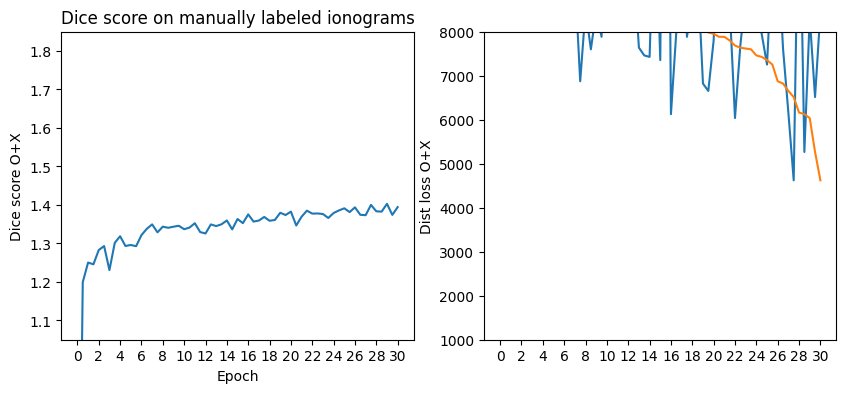

In [24]:
# evalresult = evalresult_filtered
loss = [evalresult[l] for l in evalresult]
filenames = [l for l in evalresult]

# plt.plot(np.log10(loss))
# print(filenames)

# temp = sorted(evalresult, key=lambda e : evalresult[e], reverse=True)
def key_func(s: str) -> float:
    segs = s.split('_')
    return float(segs[3])+float(segs[4])/36000

sort_by_epoch = sorted(evalresult, key=key_func, reverse=False)
sort_by_loss = sorted(evalresult, key=lambda e : evalresult[e], reverse=True)

# print(sort_by_epoch)
# print(sort_by_loss)
data = torch.load(saved_model_dir+sort_by_epoch[-1])
test_losses = data['test_loss']
sort_by_dice = [sort_by_epoch[j] for j in sorted(list(range(len(test_losses))), key=lambda i : test_losses[i], reverse=False)]
print(sort_by_dice[-5:])

fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(10, 4))
ax = axs[0]
ax.plot(test_losses)
ax.set_ylim(1.05,1.85)
ax.set_xticks(np.arange(0,len(sort_by_loss)+1,4),[f'{t:.0f}' for t in np.arange(0,len(sort_by_loss)+1,4)*0.5])
ax.set_ylabel('Dice score O+X')
ax.set_xlabel('Epoch')
ax.set_title('Dice score on manually labeled ionograms')

ax = axs[1]
ax.plot([evalresult[t] for t in sort_by_epoch])
ax.plot([evalresult[t] for t in sort_by_loss])
ax.set_ylim(1000,8000)
ax.set_ylabel('Dist loss O+X')
ax.set_xticks(np.arange(0,len(sort_by_loss)+1,4),[f'{t:.0f}' for t in np.arange(0,len(sort_by_loss)+1,4)*0.5])

print(sort_by_loss[-5:])

/tmp/ipykernel_876244/2467138151.py:21: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(0,0.1)
/tmp/ipykernel_876244/2467138151.py:30: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(0,0.1)


Text(0, 0.5, 'Dice score O+X')

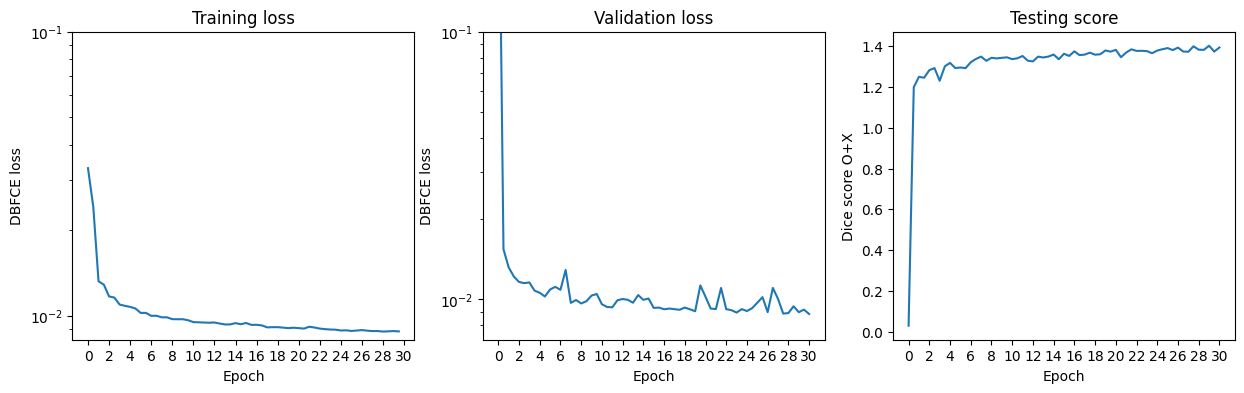

In [25]:
data = torch.load(saved_model_dir+sort_by_epoch[-1])

test_losses = data['test_loss']
val_losses = data['val_loss']
losses = data['train_loss']

# data = torch.load('saved_model/'+'TOPHAT_checkpoint_epoch_30_25000_loss1.0700.pth')

# test_losses += data['test_loss']
# val_losses += data['val_loss']
# losses += data['train_loss']

fig, axs = plt.subplots(ncols=3, nrows=1, figsize=(15, 4))
ax = axs[0]
ax.plot(losses)
ax.set_xlabel('Epoch')
ax.set_xticks(np.arange(0,len(sort_by_loss)+1,4),[f'{t:.0f}' for t in np.arange(0,len(sort_by_loss)+1,4)*0.5])
ax.set_ylabel('DBFCE loss')
ax.set_title('Training loss')
ax.set_yscale('log')
ax.set_ylim(0,0.1)
# ax.set_yscale('log')
ax = axs[1]
ax.plot(val_losses)
ax.set_xlabel('Epoch')
ax.set_xticks(np.arange(0,len(sort_by_loss)+1,4),[f'{t:.0f}' for t in np.arange(0,len(sort_by_loss)+1,4)*0.5])
ax.set_ylabel('DBFCE loss')
ax.set_title('Validation loss')
ax.set_yscale('log')
ax.set_ylim(0,0.1)
# ax.set_yscale('log')
ax = axs[2]
ax.plot(test_losses)
# ax.plot([evalresult[t] for t in temp1])
ax.set_xlabel('Epoch')
ax.set_xticks(np.arange(0,len(sort_by_loss)+1,4),[f'{t:.0f}' for t in np.arange(0,len(sort_by_loss)+1,4)*0.5])
ax.set_title('Testing score')
ax.set_ylabel('Dice score O+X')
# ax.set_ylim(1.5,1.7)

# ax.set_yscale('log')
# fig.savefig(f'losses.png', bbox_inches='tight')
# plt.close()

In [6]:
a = torch.tensor([0,0.5,0],dtype=torch.float32)
b = torch.tensor([1,0,0],dtype=torch.float32)
c = torch.logical_or(a,b)
print(c)
print(a,b)
c*torch.tensor([2,2,1])

tensor([ True,  True, False])
tensor([0.0000, 0.5000, 0.0000]) tensor([1., 0., 0.])


tensor([2, 2, 0])

In [7]:
# model = UNet(n_channels=3, n_classes=4, up_kernel_size=3)
target_size = [512,408]
model = UNet(n_channels=1, n_classes=4, input_size=target_size, in_dropout_p = 0.35, dropout_p=0.35)
# model = TransformerNet(n_channels=1, n_classes=4,input_size=target_size, in_dropout_p = 0.25, dropout_p=0.3)
# model.load_state_dict(torch.load('saved_model/TOPHAT_checkpoint_epoch_20_5_loss1.0486.pth')['model_state_dict'])
model.load_state_dict(torch.load('saved_model/'+'TOPHAT_checkpoint_epoch_28_22500_loss1.4002.pth')['model_state_dict'])
model = model.to(device=device)
model.eval()

UNet(
  (att): Transformer(
    (in_linear): Linear(in_features=512, out_features=1024, bias=True)
    (out_linear): Linear(in_features=1024, out_features=1024, bias=True)
    (blocks): Sequential(
      (0): Transformer_element(
        (c_attn): Linear(in_features=1024, out_features=3072, bias=False)
        (mlp): Sequential(
          (0): Linear(in_features=1024, out_features=1024, bias=False)
          (1): ReLU(inplace=True)
        )
        (mhatt): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=1024, out_features=1024, bias=True)
        )
        (relu): ReLU(inplace=True)
        (ln): GroupNorm(1, 408, eps=1e-05, affine=True)
      )
      (1): Transformer_element(
        (c_attn): Linear(in_features=1024, out_features=3072, bias=False)
        (mlp): Sequential(
          (0): Linear(in_features=1024, out_features=1024, bias=False)
          (1): ReLU(inplace=True)
        )
        (mhatt): MultiheadAttention(
          (out_proj):

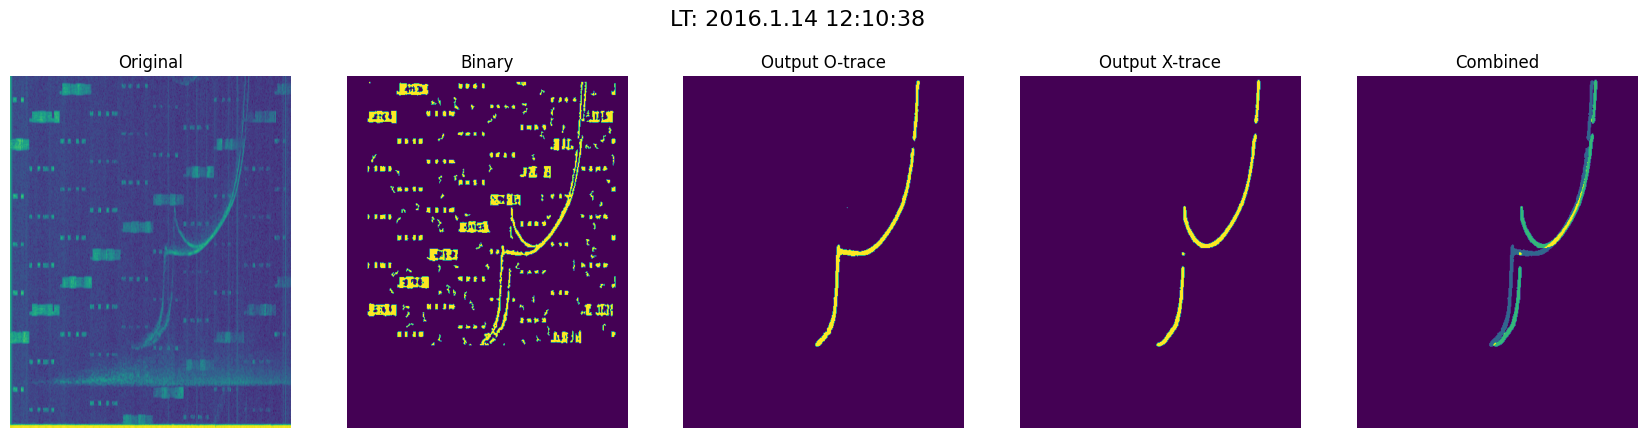

In [9]:
import glob
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)

# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    
    file = testfiles[np.random.randint(0,len(testfiles)-1)]
    testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

    orgdata = np.load('VIPIR_PROC/org/' + file, allow_pickle=True, fix_imports=True)[()]
    # for i in orgdata:
    #     print(i)
    timestruct = orgdata['vipirTimeSct']
    localtime = f"LT: {timestruct['start_year'][0]:4d}.{timestruct['start_month'][0]:d}.{timestruct['start_day'][0]:d} {timestruct['start_hour'][0]-5:2d}:{timestruct['start_minute'][0]:2d}:{timestruct['start_second'][0]:2d}"

    # print(timestruct)
    
    testimage1 = torch.from_numpy(testdata['mask_full']).float()
    testimage1 = testimage1[None,None,:,:]# resize_tr(testimage1[None,None,:,:])
    img = testimage1 #torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
    img = img.to('cuda')
    label1 = model(img)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu()
    
    fig, axs = plt.subplots(ncols=5, nrows=1, figsize=(21, 5))
    # plt.title(f'epoch{epoch_num}_{file}')
    fig.suptitle(f'{localtime}', fontsize=16)

    ax = axs[0]
    ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Original')

    ax = axs[1]
    ax.imshow(testimage1.detach().squeeze(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Binary')
    
    ax = axs[2]
    ax.imshow(imgO.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output O-trace')

    ax = axs[3]
    ax.imshow(imgX.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output X-trace')

    ax = axs[4]
    ax.imshow(imgO.numpy() + 2*imgX.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Combined')
# resize_back = transforms.Resize(ionogram.shape)


In [60]:
testdata = np.load('VIPIR_PROC/proc/' + testfiles[-1], allow_pickle=True, fix_imports=True)[()]
for i in testdata: print(i)

original
mask_full


In [12]:
d = np.load('JM91J_2016014141141.npy', allow_pickle=True)[()]
freqs = d['vipir_freqs']
hts = d['vipir_hts']

In [16]:
batchsize = 10

testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)
# resize_back = transforms.Resize(ionogram.shape)
all_filenames = []
all_imgOs = []
all_imgXs = []

with torch.inference_mode():
    for ii in range(len(testfiles)//batchsize):
        img = []
        names = []
        for jj in range(batchsize):
            file = testfiles[ii*batchsize + jj]
            testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]
            testimage = torch.from_numpy(testdata['mask_full']).float()
            testimage = testimage[None,None,:,:]
            img += [testimage]
            names += [file]

        img = torch.cat(img,dim=0)
        img = img.to('cuda')
        label = model(img)

        for i in range(batchsize):
            img1,label1 = img[i],label[i]
            label1 = label1.squeeze().to('cpu')
            imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().numpy()
            imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().numpy()
            all_filenames += [names[i]]
            all_imgOs += [imgO]
            all_imgXs += [imgX]
        # break
    del label; del img; del names    

def save_seg_result(idx, all_filenames, all_imgOs, all_imgXs):

    testdata = np.load('VIPIR_PROC/proc/' + all_filenames[idx], allow_pickle=True, fix_imports=True)[()]
    orgdata = np.load('VIPIR_PROC/org/' + all_filenames[idx], allow_pickle=True, fix_imports=True)[()]
    timestruct = orgdata['vipirTimeSct']
    localtime = f"LT: {timestruct['start_year'][0]:4d}.{timestruct['start_month'][0]:d}.{timestruct['start_day'][0]:d} {timestruct['start_hour'][0]-5:2d}:{timestruct['start_minute'][0]:2d}:{timestruct['start_second'][0]:2d}"

    fig, axs = plt.subplots(ncols=5, nrows=1, figsize=(22, 5))

    fig.suptitle(f'{localtime}',fontsize=16)

    ax = axs[0]
    ax.imshow(testdata['mask_full'], origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Binarized Ionogram')
    
    ax = axs[1]
    ax.imshow(all_imgOs[idx], origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output O-trace')

    ax = axs[2]
    ax.imshow(all_imgXs[idx], origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output X-trace')

    ax = axs[3]
    ax.pcolormesh(freqs,hts,all_imgOs[idx] + 2*all_imgXs[idx],shading='auto')
    ax.set_xlabel('Freq [MHz]')
    ax.set_ylabel('Heights [km]')
    # ax.imshow(imgO + 2*imgX, origin='lower', aspect = 'equal')
    # ax.axis('off')
    ax.set_title('Combined')

    ax = axs[4]
    ax.pcolormesh(freqs,hts,np.log10(testdata['original']),shading='auto')
    ax.set_xlabel('Freq [MHz]')
    ax.set_ylabel('Heights [km]')
    # ax.imshow(np.log10(orgins[i]), origin='lower', aspect = 'equal')
    # ax.axis('off')
    ax.set_title('VIPIR Ionogram')

    plt.savefig(f'seg_result_transformer/{all_filenames[idx][:-4]}.png', bbox_inches='tight')
    plt.close()

    np.save(f'seg_result_transformer/{all_filenames[idx]}', {'filename':all_filenames[idx], 'imgO': imgO, 'imgX': imgX})        


para_func = lambda idx: save_seg_result(idx, all_filenames, all_imgOs, all_imgXs)
# para_func(3)
losses = Parallel(n_jobs=mp.cpu_count()-4)(delayed(para_func)(idx) for idx in range(len(all_filenames)))

In [65]:
print(len(all_filenames))

1830


In [ ]:
# with torch.no_grad():
#     for file in testfiles:
#         # file = testfiles[np.random.randint(0,len(testfiles)-1)]
#         testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

#         testimage1 = torch.from_numpy(testdata['mask_full']).float()

#         orgdata = np.load('VIPIR_PROC/org/' + file, allow_pickle=True, fix_imports=True)[()]
#         timestruct = orgdata['vipirTimeSct']
#         localtime = f"LT: {timestruct['start_year'][0]:4d}.{timestruct['start_month'][0]:d}.{timestruct['start_day'][0]:d} {timestruct['start_hour'][0]-5:2d}:{timestruct['start_minute'][0]:2d}:{timestruct['start_second'][0]:2d}"
#         # testimage1 = resize_tr(testimage1[None,None,:,:])
#         # img = torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
#         img = testimage1[None,None,:,:]
#         img = img.to('cuda')
#         label1 = model(img)
#         label1 = label1.squeeze().detach().cpu()

#         imgO = torch.argmax(label1[0:2,:,:],dim=0)
#         imgX = torch.argmax(label1[2:4,:,:],dim=0)
#         imgO = imgO[None,:,:].squeeze().numpy() # resize_back(imgO[None,:,:]).squeeze().numpy()
#         imgX = imgX[None,:,:].squeeze().numpy() # resize_back(imgX[None,:,:]).squeeze().numpy()
#         testimage1 = testimage1.detach().squeeze().numpy()
        
#         fig, axs = plt.subplots(ncols=5, nrows=1, figsize=(21, 5))

#         fig.suptitle(f'{localtime}',fontsize=16)


#         ax = axs[0]
#         ax.imshow(testimage1, origin='lower', aspect = 'equal')
#         ax.axis('off')
#         ax.set_title('Binarized Ionogram')
        
#         ax = axs[1]
#         ax.imshow(imgO, origin='lower', aspect = 'equal')
#         ax.axis('off')
#         ax.set_title('Output O-trace')

#         ax = axs[2]
#         ax.imshow(imgX, origin='lower', aspect = 'equal')
#         ax.axis('off')
#         ax.set_title('Output X-trace')

#         ax = axs[3]
#         ax.imshow(imgO + 2*imgX, origin='lower', aspect = 'equal')
#         ax.axis('off')
#         ax.set_title('Combined')

#         ax = axs[4]
#         ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal')
#         ax.axis('off')
#         ax.set_title('VIPIR Ionogram')

#         plt.savefig(f'seg_result_transformer/{file[:-4]}.png', bbox_inches='tight')
#         plt.close()

#         np.save(f'seg_result_transformer/{file}', {'filename':file, 'image':testimage1, 'imgO': imgO, 'imgX': imgX})

In [ ]:


testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)
# resize_back = transforms.Resize(ionogram.shape)
# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    for file in testfiles:
        # file = testfiles[np.random.randint(0,len(testfiles)-1)]
        testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

        testimage1 = torch.from_numpy(testdata['mask_full']).float()
        # testimage1 = resize_tr(testimage1[None,None,:,:])
        # img = torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
        img = testimage1[None,None,:,:]
        img = img.to('cuda')
        label1 = model(img)
        label1 = label1.squeeze().detach().cpu()

        imgO = torch.argmax(label1[0:2,:,:],dim=0)
        imgX = torch.argmax(label1[2:4,:,:],dim=0)
        imgO = imgO[None,:,:].squeeze().numpy() # resize_back(imgO[None,:,:]).squeeze().numpy()
        imgX = imgX[None,:,:].squeeze().numpy() # resize_back(imgX[None,:,:]).squeeze().numpy()
        testimage1 = testimage1.detach().squeeze().numpy()
        
        fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 7))
        plt.title(f'{file}')
        ax = axs[0]
        ax.imshow(testimage1, origin='lower', aspect = 'auto')
        ax.axis('off')
        ax = axs[1]

        ax.imshow(imgO + imgX*2, origin='lower', aspect = 'auto')
        ax.axis('off')

        plt.savefig(f'seg_result_transformer/{file[:-4]}.png', bbox_inches='tight')
        plt.close()

        np.save(f'seg_result_transformer/{file}', {'filename':file, 'image':testimage1, 'imgO': imgO, 'imgX': imgX})

In [ ]:
from scipy import ndimage
from skimage import morphology

import glob
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)

# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    
    file = testfiles[np.random.randint(0,len(testfiles)-1)]
    testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

    testimage1 = torch.from_numpy(testdata['mask_full']).float()
    testimage1 = testimage1[None,None,:,:]# resize_tr(testimage1[None,None,:,:])
    img = testimage1 #torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
    img = img.to('cuda')
    label1 = model(img)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu()
    
    original = testdata['original']
    original -= (np.min(original)-1)
    original[np.isnan(original)] = 1

    temp1 = np.log10(original)

    sigma1 = 0.85
    sigma2 = 3

    gauss1 = ndimage.gaussian_filter(temp1,sigma1)
    gauss2 = ndimage.gaussian_filter(temp1,sigma2)
    out = gauss1-gauss2

    thresh = out > np.percentile(out,80,axis=0)
    
    temp3 = morphology.remove_small_objects(thresh, min_size=20, connectivity=1)
    # structure = np.ones([3,1])
    # temp = ndimage.binary_closing(temp3, structure)

    fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(21, 7))
    # plt.title(f'epoch{epoch_num}_{file}')

    ax = axs[0]
    ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal', cmap='gray')
    ax.axis('off')
    ax.set_title('Original')

    ax = axs[2]
    ax.imshow(testimage1.detach().squeeze(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Binary')
    
    ax = axs[1]
    ax.imshow(out, origin='lower', aspect = 'equal', cmap='gray')
    ax.axis('off')
    ax.set_title('Difference of Gaussian')

    # ax = axs[3]
    # ax.imshow(imgX.numpy(), origin='lower', aspect = 'equal')
    # ax.axis('off')
    # ax.set_title('Output X-trace')

    ax = axs[3]
    imgO[imgX>0] = 2
    ax.imshow(imgO.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Segmentation')

# resize_back = transforms.Resize(ionogram.shape)